# Select the PPSA snow pits for Table 2

Edit the two dates in **Publication pit dates** and run this notebook. After
checking the selected field days and model snapshots, it writes the shared
selection used by [Figure 5](figure5_publication.ipynb),
[Figure 6](figure6_publication.ipynb), and [Table 2](../../tables/table2_publication.ipynb).
Rerun those notebooks to refresh their outputs.

The candidate table lists all available field days and their measured mean snow
temperatures. The [all-pit comparison](figuresX_all_snowpits.ipynb) shows all
profiles and ranks their agreement with the simulations. The previews below
compare your selected dates against the same two soil simulations as Table 2.

In [1]:
import mmap
from pathlib import Path
from tempfile import NamedTemporaryFile

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.collections import PolyCollection
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.patches import Rectangle
import numpy as np
import pandas as pd

root = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'tables/table2_publication.ipynb').is_file())
output_dir = root / 'figures/files'
model_dir = Path('/home/cassie/python/models/run_snowpack/sites/ppsa/output')
field_file = root / 'figures/data/ppsa_snowpit_profiles_WY2025.csv'

model_files = {
    'HRRR-AK': model_dir / 'hrrrak_lapserate_ppsa_WY2020-WY2025_soil.pro',
    'Met mixed': model_dir / 'met_hrrrak_lapserate_ppsa_WY2020-WY2025_soil.pro',
}

## Publication pit dates

In [2]:
selected_dates = ('2025-02-16', '2025-02-27')  # Choose two distinct field dates, in display order.

field = pd.read_csv(field_file, parse_dates=['date']).set_index('date')
snow_points = field.loc[field['temperature_location'].isin(['snow', 'surface'])]

def mean_snow_temperature(rows):
    points = rows.groupby('temperature_height_cm')['temperature_c'].mean().dropna()
    if len(points) < 2:
        raise ValueError('Expected at least two measured snow or surface heights.')
    return np.trapezoid(points.to_numpy(), points.index) / (points.index[-1] - points.index[0])

candidates = pd.DataFrame([
    (date, mean_snow_temperature(rows)) for date, rows in snow_points.groupby(level=0)
], columns=['date', 'observed_mean_temperature_c']).set_index('date')
candidates['pit_class'] = np.where(candidates['observed_mean_temperature_c'] >= -1, 'warm', 'cold')
display(candidates.round(2))

dates = pd.DatetimeIndex(pd.to_datetime(list(selected_dates))).normalize()
if len(dates) != 2 or not dates.is_unique or not dates.isin(candidates.index).all():
    raise ValueError('Choose two distinct dates from the candidate table.')
selected = candidates.loc[dates].rename_axis('date').reset_index()
selected['model_time'] = selected['date'] + pd.Timedelta(hours=12)
pits = [(f'{row.pit_class.capitalize()} pit', row.model_time)
        for row in selected.itertuples(index=False)]

,observed_mean_temperature_c,pit_class
date,,
2025-01-23,-0.01,warm
2025-01-28,-4.00,cold
2025-02-12,-8.86,cold
2025-02-16,-3.54,cold
2025-02-20,-0.99,warm
2025-02-27,0.10,warm
2025-03-06,-3.97,cold
2025-03-13,-0.43,warm
2025-03-16,-1.38,cold


## Load the model and observation columns

The [tidy field CSV](../data/ppsa_snowpit_profiles_WY2025.csv) contains density
intervals and point temperatures for all ten field days, with the source tab and
row recorded for each measurement. The [extractor](../scripts/extract_ppsa_snowpit_profiles.py)
reads the field workbook and uses its post-processed density column. It also
retains the primary and extra cutter weights where they were recorded. The two
metadata tabs and the stratigraphy and grain-size columns are outside this
extraction.

Both field and model heights are converted to depth below the snow surface.
Model properties retain their original layer thicknesses above the soil surface.
The plot includes the measured snow and surface temperatures. Air and ground
measurements remain in the CSV.

In [3]:
def read_profile(path, timestamp):
    prefix = timestamp.strftime('0500,%d.%m.%Y %H:%M:%S').encode()
    fields = {}
    with path.open('rb') as stream, mmap.mmap(stream.fileno(), 0, access=mmap.ACCESS_READ) as data:
        start = data.find(prefix)
        if start < 0:
            raise ValueError(f'No exact profile at {timestamp} in {path.name}')
        data.seek(start)
        data.readline()
        for line in iter(data.readline, b''):
            if line.startswith(b'0500,'):
                break
            if line.startswith((b'0501,', b'0502,', b'0503,')):
                key, count, payload = line.split(b',', 2)
                values = np.fromstring(payload.decode(), sep=',')
                if len(values) != int(count):
                    raise ValueError(f'Invalid {key!r} element count in {path.name}')
                fields[key] = values
    heights, density, temperature = (fields[k] for k in (b'0501', b'0502', b'0503'))
    if len(heights) != len(density) + 1 or len(density) != len(temperature):
        raise ValueError(f'Unexpected soil profile geometry in {path.name}')
    snow = heights[1:] > 0
    lower = np.maximum(heights[:-1][snow], 0)
    upper = heights[1:][snow]
    if not len(upper) or np.any(upper <= lower):
        raise ValueError(f'No ordered snow layers at {timestamp} in {path.name}')
    return pd.DataFrame({
        'top_cm': upper[-1] - upper,
        'bottom_cm': upper[-1] - lower,
        'density_kg_m3': density[snow],
        'temperature_c': temperature[snow],
    }).iloc[::-1].reset_index(drop=True)

In [4]:
profiles = {
    time: {name: read_profile(path, time) for name, path in model_files.items()}
    for _, time in pits
}
bounds = ['top_cm', 'bottom_cm']

# Replace the publication selection only after both dates load in both simulations.
selection_file = root / 'figures/data/ppsa_snowpit_selection_WY2025.csv'
columns = ['pit_class', 'date', 'model_time', 'observed_mean_temperature_c']
with NamedTemporaryFile(mode='w', dir=selection_file.parent, suffix='.tmp',
                        delete=False) as temp:
    staged_selection = Path(temp.name)
    selected[columns].to_csv(temp, index=False, float_format='%.6f')
staged_selection.replace(selection_file)
display(selected[columns])

,pit_class,date,model_time,observed_mean_temperature_c
0,cold,2025-02-16,2025-02-16 12:00:00,-3.54
1,warm,2025-02-27,2025-02-27 12:00:00,0.10


## Profile columns

The continuous color ramps follow the supplied NiViz screenshot. Density
runs from pale cyan to deep blue. Temperature runs from deep blue at −20 °C
to red at 0 °C. The limits are shared across pits and simulations.
The temperature scale shows values outside −20 to 0 °C with end triangles. Repeated readings at the same height are averaged.

Density colors cover each sampled interval. Overlapping samples are shown as adjacent colors where they overlap. Temperature is linearly
interpolated between readings for display. Dots mark measured depths, and the
unmeasured base of each temperature column is left blank.


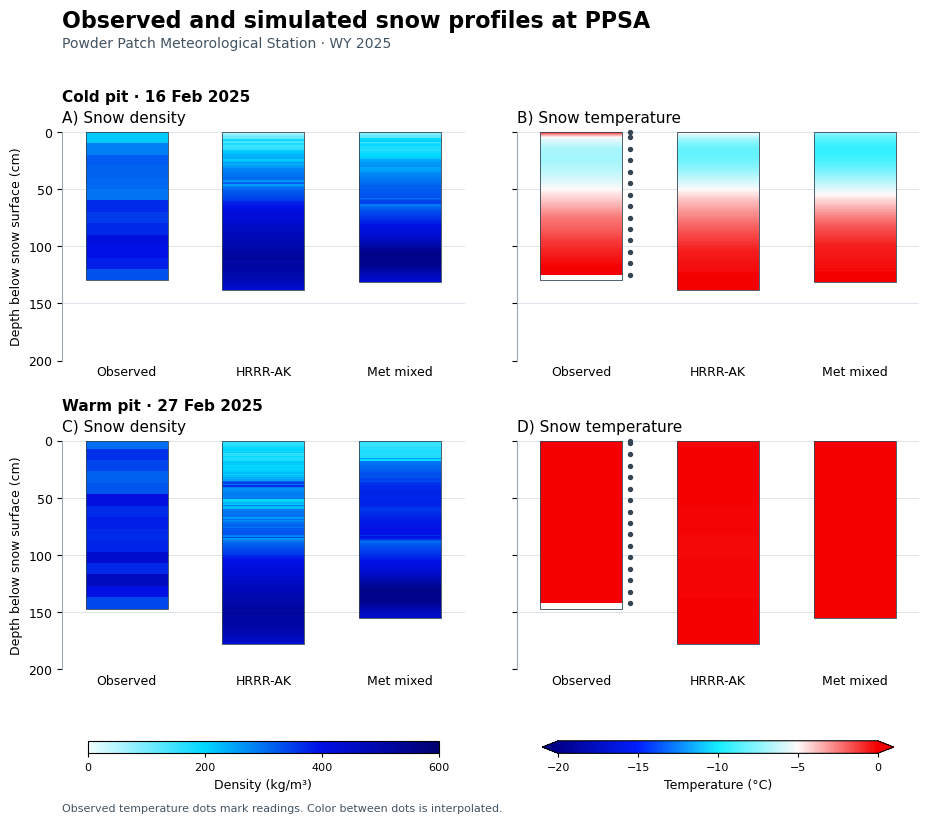

In [5]:
density_cmap = LinearSegmentedColormap.from_list(
    'density', [(0, '#f1ffff'), (0.33, '#00d8ff'), (0.66, '#000fe6'), (1, '#000071')]
)
temperature_cmap = LinearSegmentedColormap.from_list(
    'temperature', [(0, '#00008b'), (0.25, '#001fff'), (0.50, '#15efff'),
                    (0.75, '#fffafa'), (1, '#f40000')]
)
variables = {
    'density_kg_m3': ('Snow density', 'Density (kg/m³)', density_cmap, Normalize(0, 600)),
    'temperature_c': ('Snow temperature', 'Temperature (°C)', temperature_cmap, Normalize(-20, 0)),
}

def draw_bands(ax, left, right, layers, variable, cmap, norm):
    vertices = [[(lo, top), (hi, top), (hi, bottom), (lo, bottom)]
                for lo, hi, (top, bottom) in zip(
                    np.broadcast_to(left, len(layers)), np.broadcast_to(right, len(layers)),
                    layers[bounds].itertuples(index=False, name=None))]
    ax.add_collection(PolyCollection(vertices, array=layers[variable].to_numpy(),
                                     cmap=cmap, norm=norm, edgecolors='none',
                                     antialiaseds=False, zorder=2))


def observed_density(rows, depth):
    density = rows.loc[rows['measurement'].eq('density')]
    top = depth - density['top_height_cm'].to_numpy()
    bottom = depth - density['bottom_height_cm'].to_numpy()
    edges = np.unique(np.r_[top, bottom])
    bands = []
    for shallow, deep in zip(edges[:-1], edges[1:]):
        values = density.loc[(top <= shallow) & (bottom >= deep), 'density_kg_m3']
        slots = np.linspace(-0.30, 0.30, len(values) + 1)
        bands.extend((lo, hi, shallow, deep, value)
                     for lo, hi, value in zip(slots[:-1], slots[1:], values))
    return pd.DataFrame(bands, columns=['left', 'right', *bounds, 'density_kg_m3'])


def observed_temperature(rows, depth):
    points = rows.loc[rows['temperature_location'].isin(['snow', 'surface'])]
    points = points.assign(depth_cm=depth - points['temperature_height_cm'])
    points = points.groupby('depth_cm', as_index=False)['temperature_c'].mean()
    if len(points) < 2:
        raise ValueError('Expected distinct temperature sample depths for this pit.')
    # Use fine display strips bounded by the depths of the first and last readings.
    edges = np.linspace(points['depth_cm'].iloc[0], points['depth_cm'].iloc[-1], 321)
    bands = pd.DataFrame({
        'top_cm': edges[:-1], 'bottom_cm': edges[1:],
        'temperature_c': np.interp((edges[:-1] + edges[1:]) / 2,
                                   points['depth_cm'], points['temperature_c']),
    })
    return bands, points


all_depths = [frame.bottom_cm.max() for model in profiles.values() for frame in model.values()]
all_depths += [field.loc[time.normalize(), 'snow_depth_cm'].max() for _, time in pits]
depth_limit = 25 * np.ceil((max(all_depths) + 5) / 25)

with mpl.rc_context({'font.family': 'DejaVu Sans', 'pdf.fonttype': 42, 'hatch.linewidth': 0.38}):
    fig, axes = plt.subplots(2, 2, figsize=(10.2, 8.4), sharey=True,
                             gridspec_kw={'left': 0.09, 'right': 0.93, 'top': 0.83,
                                          'bottom': 0.19, 'hspace': 0.35, 'wspace': 0.13})
    for col, (variable, (title, unit, cmap, norm)) in enumerate(variables.items()):
        for row, (pit, time) in enumerate(pits):
            ax = axes[row, col]
            ax.set_title(f'{chr(65 + row * 2 + col)}) {title}', loc='left', fontsize=11, pad=7)
            field_day = field.loc[time.normalize()]
            depth = field_day['snow_depth_cm'].iloc[0]
            if variable == 'density_kg_m3':
                bands = observed_density(field_day, depth)
                draw_bands(ax, bands['left'], bands['right'], bands, variable, cmap, norm)
            else:
                bands, points = observed_temperature(field_day, depth)
                draw_bands(ax, -0.30, 0.30, bands, variable, cmap, norm)
                ax.scatter(np.full(len(points), 0.36), points['depth_cm'], s=8,
                           color='#344453', clip_on=False, zorder=4)
            ax.add_patch(Rectangle((-0.30, 0), 0.60, depth, fill=False,
                                   edgecolor='#344453', linewidth=0.6, zorder=3))

            for x, layers in enumerate(profiles[time].values(), 1):
                draw_bands(ax, x - 0.30, x + 0.30, layers, variable, cmap, norm)
                ax.add_patch(Rectangle((x - 0.30, 0), 0.60, layers.bottom_cm.max(),
                                       fill=False, edgecolor='#344453', linewidth=0.6, zorder=3))

            ax.set(xlim=(-0.47, 2.47), ylim=(depth_limit, 0),
                   xticks=[0, 1, 2], xticklabels=['Observed', *model_files])
            ax.set_yticks(np.arange(0, depth_limit + 1, 50))
            ax.tick_params(axis='x', length=0, labelsize=9)
            ax.tick_params(axis='y', labelsize=9)
            ax.grid(axis='y', color='#dce4eb', linewidth=0.7)
            ax.set_axisbelow(True)
            ax.spines[['top', 'right', 'bottom']].set_visible(False)
            ax.spines['left'].set_color('#9aa9b4')
            if col == 0:
                ax.set_ylabel('Depth below snow surface (cm)', fontsize=9)
                header = ax.get_position()
                fig.text(header.x0, header.y1 + 0.033, f'{pit} · {time:%-d %b %Y}',
                         ha='left', va='bottom', fontsize=11, weight='bold')

        box = axes[-1, col].get_position()
        cax = fig.add_axes([box.x0 + 0.025, 0.090, box.width - 0.05, 0.015])
        ticks = [0, 200, 400, 600] if col == 0 else [-20, -15, -10, -5, 0]
        scale = fig.colorbar(mpl.cm.ScalarMappable(norm=norm, cmap=cmap), cax=cax,
                             orientation='horizontal', ticks=ticks,
                             extend='both' if col == 1 else 'neither')
        scale.set_label(unit, fontsize=9)
        scale.ax.tick_params(labelsize=8, length=3)

    fig.text(0.09, 0.976, 'Observed and simulated snow profiles at PPSA',
             ha='left', va='top', fontsize=16, weight='bold')
    fig.text(0.09, 0.944, 'Powder Patch Meteorological Station · WY 2025',
             ha='left', va='top', fontsize=10, color='#425362')
    fig.text(0.09, 0.019, 'Observed temperature dots mark readings. Color between dots is interpolated.',
             ha='left', va='bottom', fontsize=8, color='#425362')

    for extension in ('png', 'pdf'):
        fig.savefig(output_dir / f'figureX_table2_snowpits.{extension}', dpi=300, facecolor='white')
    plt.show()

## Simplified comparison | Ground-aligned profiles

The observed and HRRR-AK columns share a zero at the ground. Each column rises
to its own snow depth. Density and temperature retain the scales and observation
plotting conventions used above.

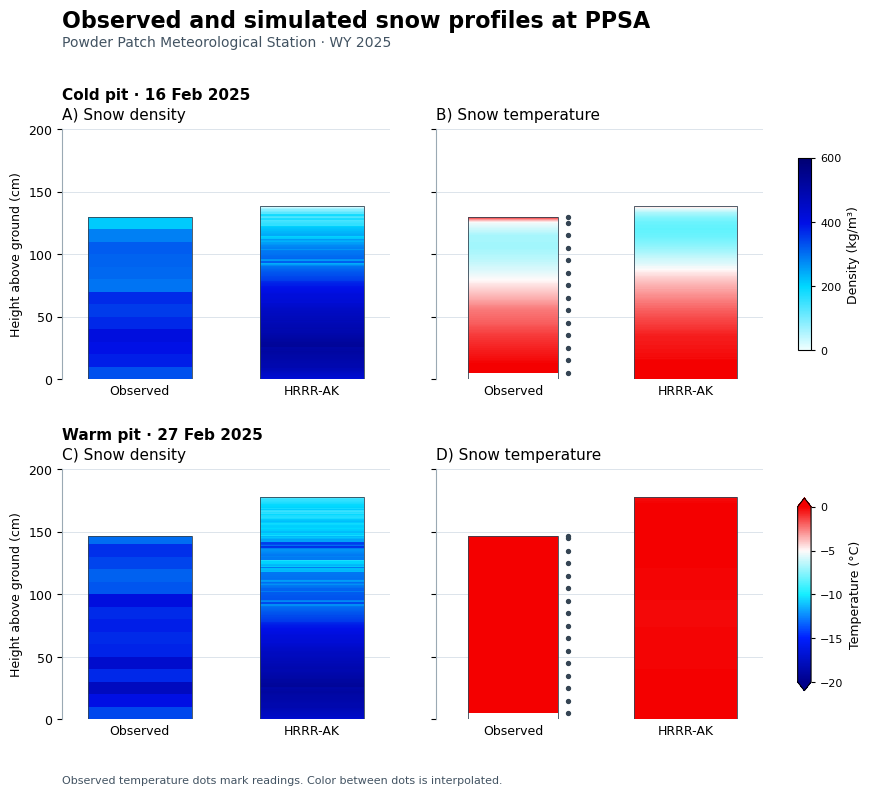

In [6]:
def height_above_ground(bands, depth):
    # The band edges are ordered from low to high on the new axis.
    return bands.assign(top_cm=depth - bands['bottom_cm'],
                        bottom_cm=depth - bands['top_cm'])


with mpl.rc_context({'font.family': 'DejaVu Sans', 'pdf.fonttype': 42}):
    fig_ground, axes_ground = plt.subplots(
        2, 2, figsize=(9.6, 8.2), sharey=True,
        gridspec_kw={'left': 0.10, 'right': 0.83, 'top': 0.83, 'bottom': 0.11,
                     'hspace': 0.36, 'wspace': 0.14},
    )

    for col, (variable, (title, unit, cmap, norm)) in enumerate(variables.items()):
        for row, (pit, time) in enumerate(pits):
            ax = axes_ground[row, col]
            field_day = field.loc[time.normalize()]
            obs_depth = field_day['snow_depth_cm'].iloc[0]
            if variable == 'density_kg_m3':
                bands = height_above_ground(observed_density(field_day, obs_depth), obs_depth)
                draw_bands(ax, bands['left'], bands['right'], bands, variable, cmap, norm)
            else:
                bands, points = observed_temperature(field_day, obs_depth)
                draw_bands(ax, -0.26, 0.26, height_above_ground(bands, obs_depth),
                           variable, cmap, norm)
                ax.scatter(np.full(len(points), 0.32), obs_depth - points['depth_cm'],
                           s=8, color='#344453', zorder=4)

            model = profiles[time]['HRRR-AK']
            model_depth = model['bottom_cm'].max()
            draw_bands(ax, 0.70, 1.30, height_above_ground(model, model_depth),
                       variable, cmap, norm)
            obs_width = 0.60 if variable == 'density_kg_m3' else 0.52
            for center, width, depth in [(0, obs_width, obs_depth), (1, 0.60, model_depth)]:
                ax.add_patch(Rectangle((center - width / 2, 0), width, depth, fill=False,
                                       edgecolor='#344453', linewidth=0.6, zorder=3))

            ax.set_title(f'{chr(65 + row * 2 + col)}) {title}', loc='left', fontsize=11, pad=7)
            ax.set(xlim=(-0.45, 1.45), ylim=(0, depth_limit),
                   xticks=[0, 1], xticklabels=['Observed', 'HRRR-AK'])
            ax.set_yticks(np.arange(0, depth_limit + 1, 50))
            ax.tick_params(axis='x', length=0, labelsize=9)
            ax.tick_params(axis='y', labelsize=9)
            ax.grid(axis='y', color='#dce4eb', linewidth=0.7)
            ax.set_axisbelow(True)
            ax.spines[['top', 'right', 'bottom']].set_visible(False)
            ax.spines['left'].set_color('#9aa9b4')
            if col == 0:
                ax.set_ylabel('Height above ground (cm)', fontsize=9)
                panel = ax.get_position()
                fig_ground.text(panel.x0, panel.y1 + 0.033,
                                f'{pit} · {time:%-d %b %Y}', ha='left',
                                va='bottom', fontsize=11, weight='bold')

        panel = axes_ground[col, -1].get_position()
        cax = fig_ground.add_axes([0.866, panel.y0 + 0.035, 0.014, panel.height - 0.07])
        ticks = [0, 200, 400, 600] if col == 0 else [-20, -15, -10, -5, 0]
        scale = fig_ground.colorbar(mpl.cm.ScalarMappable(norm=norm, cmap=cmap),
                                    cax=cax, orientation='vertical', ticks=ticks,
                                    extend='both' if col == 1 else 'neither')
        scale.set_label(unit, fontsize=9)
        scale.ax.tick_params(labelsize=8, length=3)

    fig_ground.text(0.10, 0.976, 'Observed and simulated snow profiles at PPSA',
                    ha='left', va='top', fontsize=16, weight='bold')
    fig_ground.text(0.10, 0.944, 'Powder Patch Meteorological Station · WY 2025',
                    ha='left', va='top', fontsize=10, color='#425362')
    fig_ground.text(0.10, 0.03,
                    'Observed temperature dots mark readings. Color between dots is interpolated.',
                    ha='left', va='bottom', fontsize=8, color='#425362')
    for extension in ('png', 'pdf'):
        fig_ground.savefig(output_dir / f'figureX_table2_snowpits_ground_aligned.{extension}',
                           dpi=300, facecolor='white')
    plt.show()